# Comparison with CCLE (Splits: TMT, iTRAQ, Label-Free)

This notebook compares the 3 processed Collection A datasets against CCLE Proteomics and Transcriptomics data.
It includes statistical summaries and distribution plots to assess comparability.

In [1]:
import pandas as pd
import mygene
from joblib import load
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import pearsonr, spearmanr

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

In [2]:
def standardize_to_ccle_format(df_input):
    df = df_input.copy()
    # Force numeric
    df = df.apply(pd.to_numeric, errors='coerce')
    
    # Map ENSG -> Symbol using MyGene
    mg = mygene.MyGeneInfo()
    ensembl_ids = df.columns.tolist()
    
    if any(col.startswith('ENSG') for col in ensembl_ids[:5]):
        try:
            results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human', as_dataframe=True)
            mapping_dict = results['symbol'].dropna().to_dict()
            df = df.rename(columns=mapping_dict)
        except Exception:
            pass
    
    # Handle duplicates
    df = df.T.groupby(level=0).mean().T
    
    # Standardize Index
    df.index = df.index.astype(str).str.upper().str.strip()
    return df

def get_stats(df, name="Data"):
    flat = df.values.flatten()
    flat = flat[~np.isnan(flat)]
    return pd.Series({
        "Mean": np.mean(flat),
        "Median": np.median(flat),
        "Std": np.std(flat),
        "Min": np.min(flat),
        "Max": np.max(flat),
        "Zeros%": (flat == 0).mean() * 100
    }, name=name)

### Load Data & Prepare Structures

In [ ]:
print("Loading reference CCLE...")
ccle_prot = load("processed_data/proteomics_matched.joblib")
ccle_rna = load("processed_data/transcriptomics_matched.joblib")

GROUPS = ["TMT", "iTRAQ", "LabelFree"]
TYPES = ["Protein", "RNA"]

# Store data for plotting
data_store = {}

for group in GROUPS:
    data_store[group] = {}
    for dtype in TYPES:
        path = f"processed_data/Collection_A_{group}_{dtype}.csv"
        if os.path.exists(path):
            print(f"> Processing {group} {dtype}...")
            df = pd.read_csv(path, index_col=0)
            df_std = standardize_to_ccle_format(df)
            data_store[group][dtype] = df_std
        else:
            data_store[group][dtype] = None

Loading reference CCLE...
> Processing TMT Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
5 input query terms found no hit:	['ENSG00000112096', 'ENSG00000130723', 'ENSG00000148362', 'ENSG00000168078', 'ENSG00000274791']


> Processing TMT RNA...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found dup hits:	[('ENSG00000175711', 2)]
21 input query terms found no hit:	['ENSG00000069712', 'ENSG00000112096', 'ENSG00000130723', 'ENSG00000133808', 'ENSG00000148362', 'ENS


> Processing iTRAQ Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
3 input query terms found no hit:	['ENSG00000112096', 'ENSG00000148362', 'ENSG00000203812']


... (2 outputs left out)

> Processing LabelFree Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found no hit:	['ENSG00000112096']


> Processing LabelFree RNA...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found dup hits:	[('ENSG00000175711', 2)]
162 input query terms found no hit:	['ENSG00000005955', 'ENSG00000006114', 'ENSG00000017373', 'ENSG00000017621', 'ENSG00000056661', 'ENS


### Statistical Summary & Visualization


>>> STATS: TMT - Protein
          My Data       CCLE
Mean     6.608519  -0.021529
Median   0.209000  -0.023866
Std     11.368546   0.786623
Min    -21.833000 -16.951352
Max     36.041000   7.722932
Zeros%   0.051344   0.000000
    Gene Mean Correlation (Pearson): 0.0144

>>> STATS: TMT - RNA
             My Data       CCLE
Mean        9.582018   1.163717
Median      8.384000   0.028569
Std        35.787448   2.031469
Min       -11.064000   0.000000
Max     20758.532000  17.253967
Zeros%      0.001687  47.357167
    Gene Mean Correlation (Pearson): 0.3177

>>> STATS: iTRAQ - Protein
         My Data       CCLE
Mean   -0.016635  -0.021529
Median -0.002000  -0.023866
Std     0.449833   0.786623
Min    -7.054000 -16.951352
Max     6.892000   7.722932
Zeros%  0.102955   0.000000
    Gene Mean Correlation (Pearson): 0.0648

>>> STATS: iTRAQ - RNA
          My Data       CCLE
Mean    12.425519   1.163717
Median  11.344918   0.028569
Std      4.439253   2.031469
Min     -2.123434   0.000000


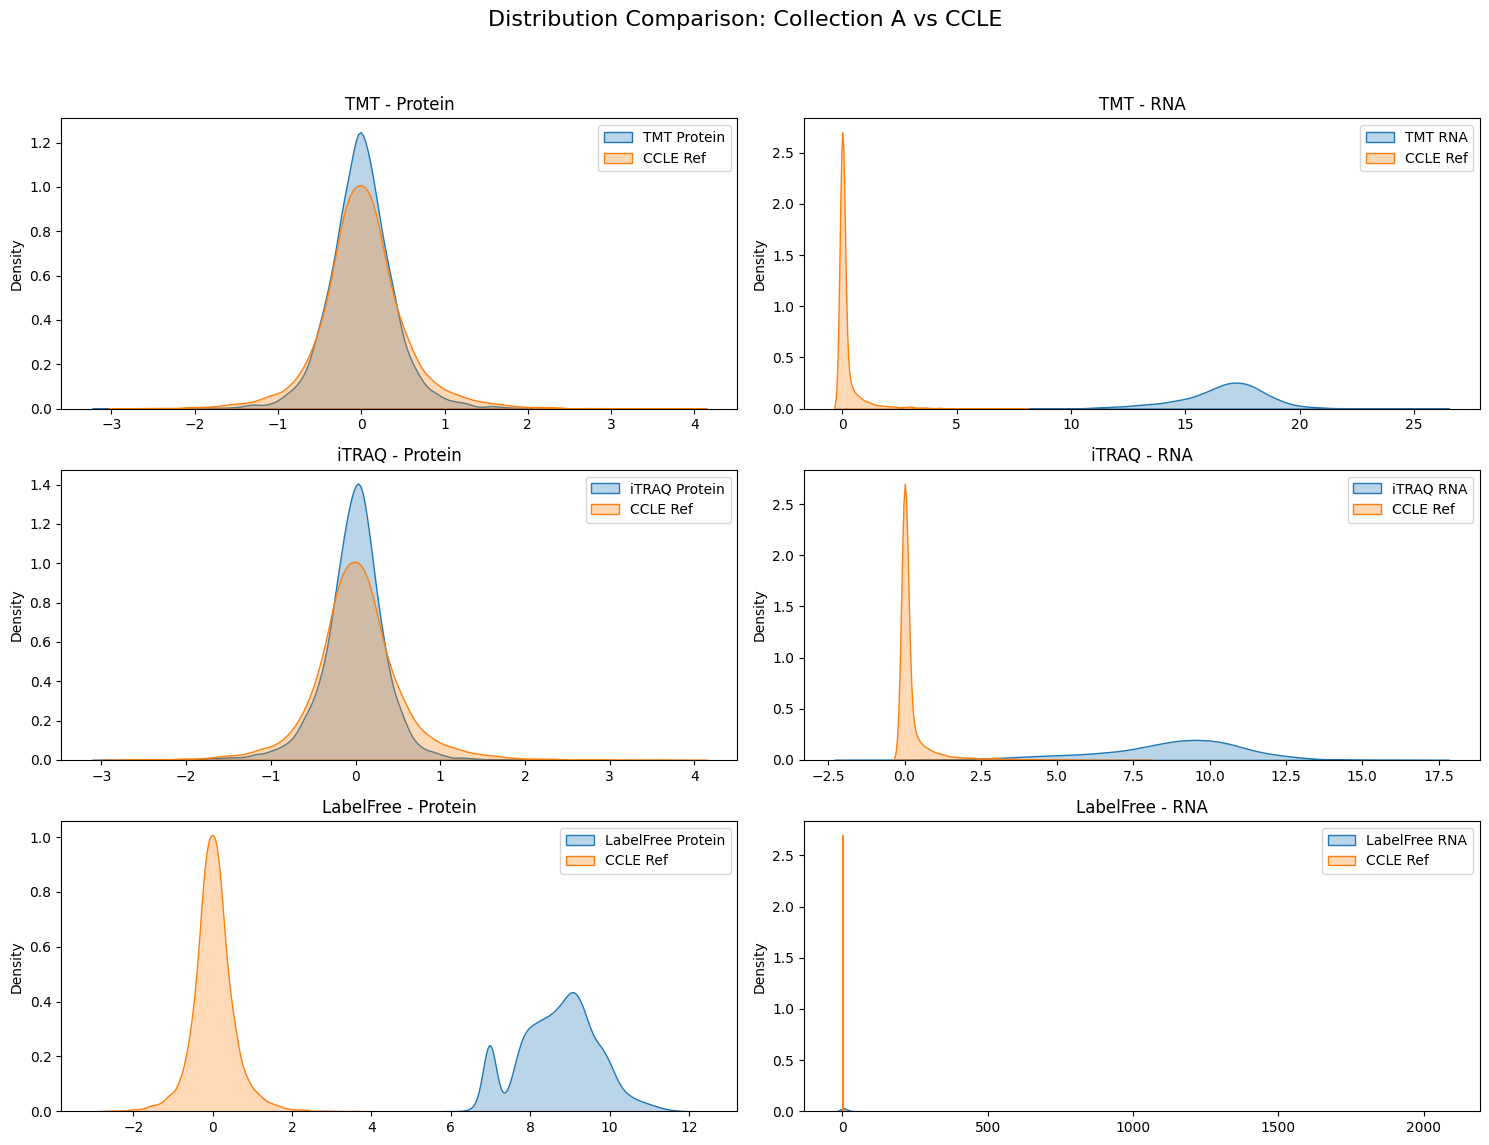

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle("Distribution Comparison: Collection A vs CCLE", fontsize=16)

for r, group in enumerate(GROUPS):
    for c, dtype in enumerate(TYPES):
        ax = axes[r][c]
        df_my = data_store[group][dtype]
        df_ref = ccle_prot if dtype == "Protein" else ccle_rna
        
        if df_my is not None:
            # 1. Plot
            # Sample subset for speed if needed, but KDE is reasonably fast
            sns.kdeplot(df_my.values.flatten()[:10000], ax=ax, label=f"{group} {dtype}", fill=True, alpha=0.3)
            sns.kdeplot(df_ref.values.flatten()[:10000], ax=ax, label="CCLE Ref", fill=True, alpha=0.3)
            ax.set_title(f"{group} - {dtype}")
            ax.legend()
            
            # 2. Stats Print
            print(f"\n>>> STATS: {group} - {dtype}")
            s1 = get_stats(df_my, "My Data")
            s2 = get_stats(df_ref, "CCLE")
            print(pd.concat([s1, s2], axis=1))
            
            # 3. Gene Correlation (Mean Expression)
            # Intersect genes first
            common = df_my.columns.intersection(df_ref.columns)
            if len(common) > 10:
                m1 = df_my[common].mean()
                m2 = df_ref[common].mean()
                corr, _ = pearsonr(m1, m2)
                print(f"    Gene Mean Correlation (Pearson): {corr:.4f}")
            
        else:
            ax.text(0.5, 0.5, "No Data", ha='center')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Filtered CCLE transcriptomics


>>> STATS: TMT - Protein
          My Data       CCLE
Mean     6.608519  -0.021529
Median   0.209000  -0.023866
Std     11.368546   0.786623
Min    -21.833000 -16.951352
Max     36.041000   7.722932
Zeros%   0.051344   0.000000
    Gene Mean Correlation (Pearson): 0.0144

>>> STATS: TMT - RNA
             My Data       CCLE
Mean        9.582018   2.592417
Median      8.384000   2.130931
Std        35.787448   2.413308
Min       -11.064000   0.000000
Max     20758.532000  17.253967
Zeros%      0.001687  11.607674
    Gene Mean Correlation (Pearson): 0.3160

>>> STATS: iTRAQ - Protein
         My Data       CCLE
Mean   -0.016635  -0.021529
Median -0.002000  -0.023866
Std     0.449833   0.786623
Min    -7.054000 -16.951352
Max     6.892000   7.722932
Zeros%  0.102955   0.000000
    Gene Mean Correlation (Pearson): 0.0648

>>> STATS: iTRAQ - RNA
          My Data       CCLE
Mean    12.425519   2.592417
Median  11.344918   2.130931
Std      4.439253   2.413308
Min     -2.123434   0.000000


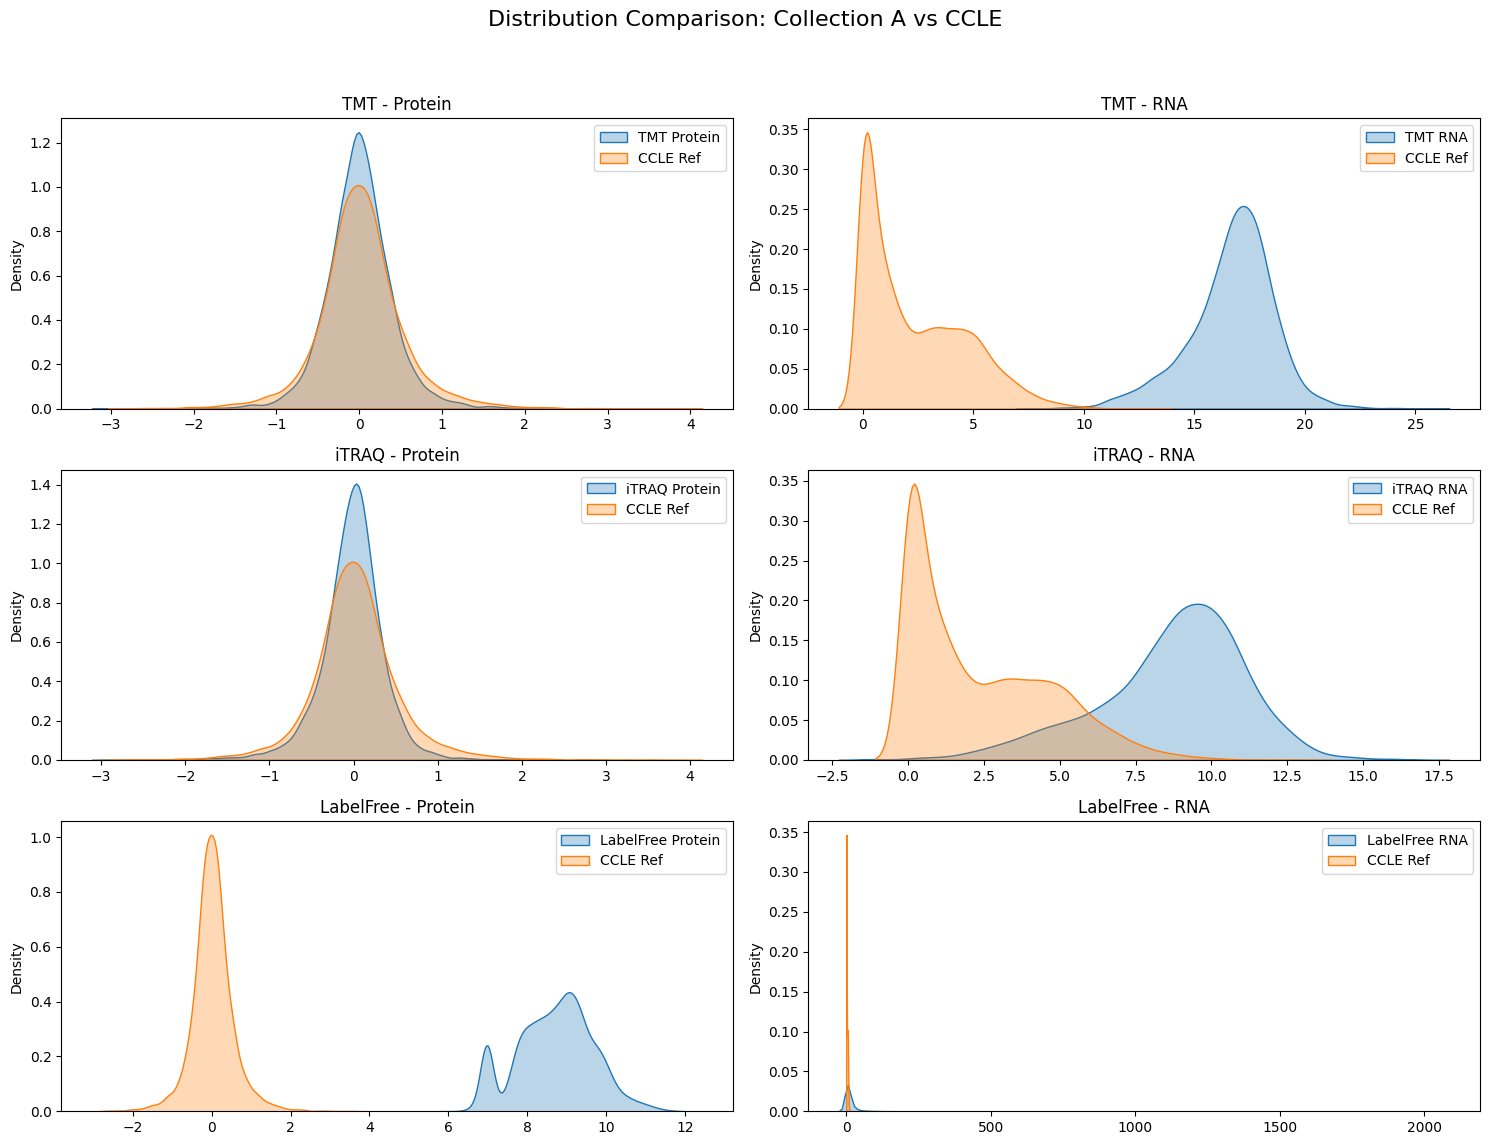

In [5]:
ccle_rna = load("processed_data/transcriptomics_filtered.joblib")
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle("Distribution Comparison: Collection A vs CCLE", fontsize=16)

for r, group in enumerate(GROUPS):
    for c, dtype in enumerate(TYPES):
        ax = axes[r][c]
        df_my = data_store[group][dtype]
        df_ref = ccle_prot if dtype == "Protein" else ccle_rna
        
        if df_my is not None:
            # 1. Plot
            # Sample subset for speed if needed, but KDE is reasonably fast
            sns.kdeplot(df_my.values.flatten()[:10000], ax=ax, label=f"{group} {dtype}", fill=True, alpha=0.3)
            sns.kdeplot(df_ref.values.flatten()[:10000], ax=ax, label="CCLE Ref", fill=True, alpha=0.3)
            ax.set_title(f"{group} - {dtype}")
            ax.legend()
            
            # 2. Stats Print
            print(f"\n>>> STATS: {group} - {dtype}")
            s1 = get_stats(df_my, "My Data")
            s2 = get_stats(df_ref, "CCLE")
            print(pd.concat([s1, s2], axis=1))
            
            # 3. Gene Correlation (Mean Expression)
            # Intersect genes first
            common = df_my.columns.intersection(df_ref.columns)
            if len(common) > 10:
                m1 = df_my[common].mean()
                m2 = df_ref[common].mean()
                corr, _ = pearsonr(m1, m2)
                print(f"    Gene Mean Correlation (Pearson): {corr:.4f}")
            
        else:
            ax.text(0.5, 0.5, "No Data", ha='center')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()